# Python DA Assignment 2 - Data Visualization

## 1) Loading the Taxis Dataset

In [14]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")

df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [2]:
df.shape

(6433, 14)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


## 2) Handling Missing Values

In [ ]:
#Check for missing values in the dataset and identify columns with missing data.

In [4]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [ ]:
#Impute missing values using appropriate strategies based on the column type (e.g.,
#using mean, median, or mode for numerical columns, and mode for categorical
#columns).

In [5]:
df.isnull().sum()[df.isnull().sum()>0]

payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [ ]:
#For columns that are critical and cannot be reasonably imputed, remove rows with
#missing values to maintain data integrity.

In [11]:

num_cols = df.select_dtypes(include='number').columns

cat_cols = df.select_dtypes(include=['object', 'str', 'category']).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

df = df.dropna(subset=['pickup'])


print(df.isnull().sum())
    
    

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [12]:
df = df.dropna(subset=['pickup'])

In [13]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

## 3) Visualizations using Matplotlib/Pandas Plot:

In [ ]:
#★ Line Chart
#Plot a line chart to visualize the fare over time, using the pickup timestamp as the
#x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime
#format before plotting.

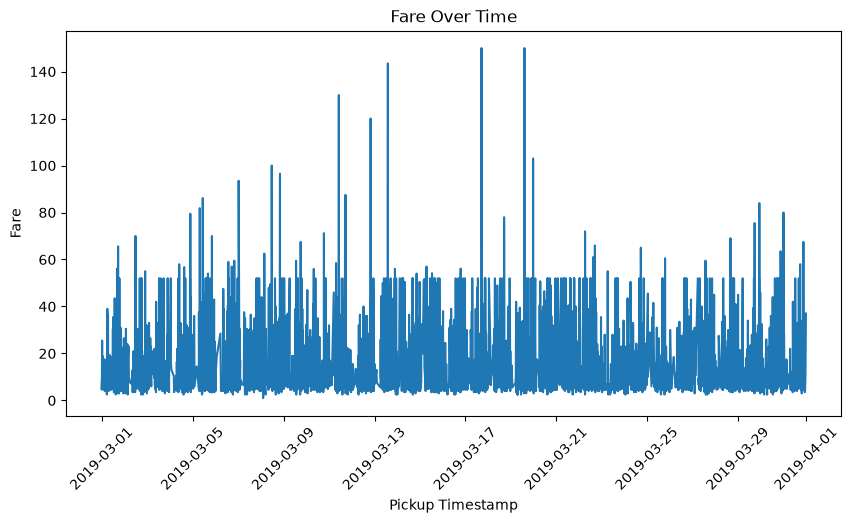

In [15]:

df['pickup'] = pd.to_datetime(df['pickup'])

df = df.sort_values('pickup')

plt.figure(figsize=(10,5))
plt.plot(df['pickup'], df['fare'])

plt.title('Fare Over Time')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Fare')
plt.xticks(rotation=45)
plt.show()

In [ ]:
#★ Bar Chart
#Create a bar chart to show the total fare for each pickup_borough. Group the data
#by pickup_borough and sum the fare for each group.

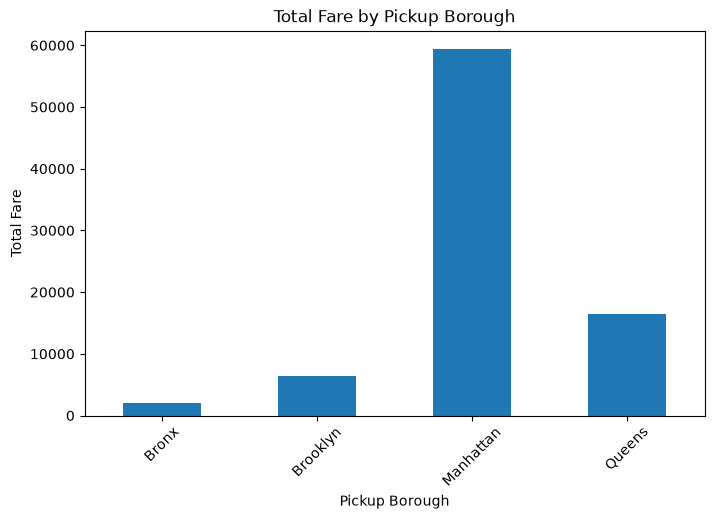

In [17]:
borough_fare =df.groupby('pickup_borough',observed=False)['fare'].sum()
borough_fare.plot(kind='bar',figsize=(8,5))

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.xticks(rotation=45)
plt.show()

In [ ]:
#★ Pie Chart
#Plot a pie chart showing the distribution of trips based on the payment method (credit
#card, cash, etc.). Each slice should represent the count of trips for a specific payment
#method.

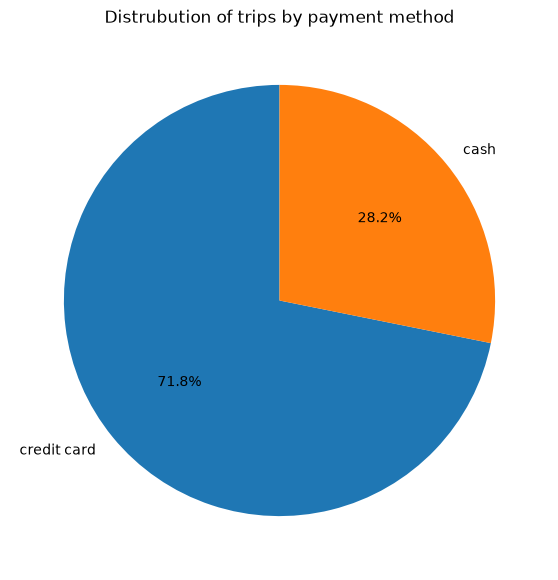

In [19]:
payment_counts = df['payment'].value_counts()

plt.figure(figsize=(7,7))
plt.pie(payment_counts,labels=payment_counts.index,autopct='%1.1f%%',startangle=90)

plt.title('Distrubution of trips by payment method')
plt.show()

In [ ]:
#★ Histogram
#Create a histogram to visualize the distribution of distance. Customize the number of
#bins for better granularity and ensure the plot is easy to interpret.

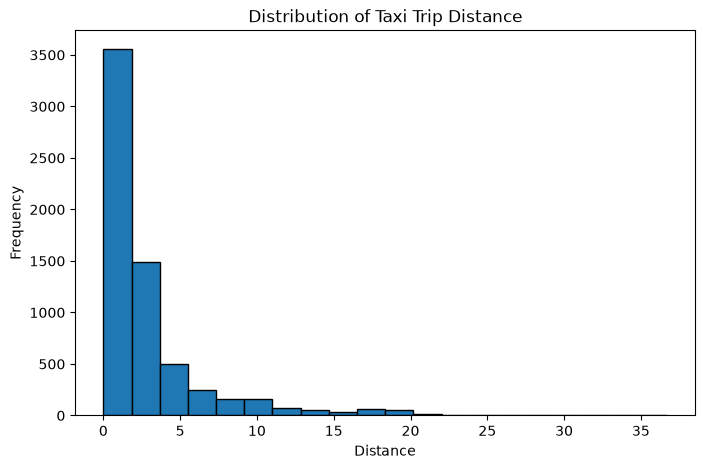

In [20]:
plt.figure(figsize=(8,5))

plt.hist(df['distance'], bins=20, edgecolor='black')

plt.title('Distribution of Taxi Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')
plt.show()

In [ ]:
#★ Box Plot
#Plot a box plot to visualize the distribution of tip amounts for each pickup_borough.
#Use pickup_borough as the categorical axis and tip as the numeric axis.

## Visualizations using Seaborn

In [ ]:
#★ Count Plot
#Create a count plot to visualize the number of trips in each pickup_borough. The
#x-axis should represent the boroughs, and the y-axis should show the count of trips.

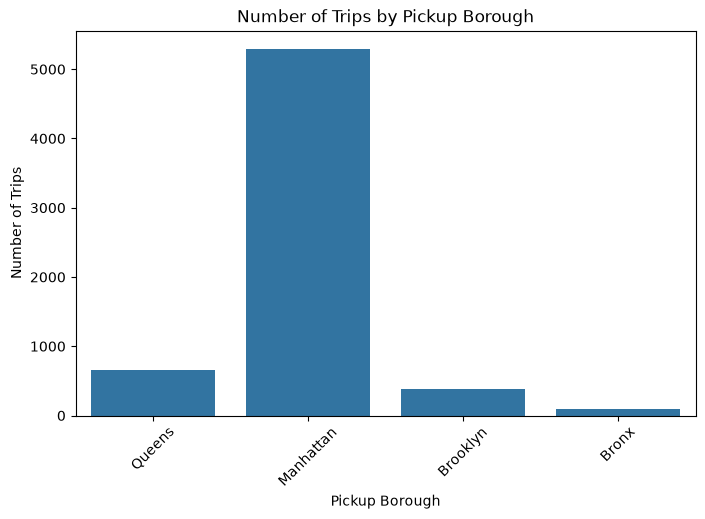

In [22]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='pickup_borough')

plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')
plt.xticks(rotation=45)
plt.show()

In [ ]:
#★ Scatter Plot
#Plot a scatter plot to show the relationship between distance and fare. Use
#distance on the x-axis and fare on the y-axis to visualize any correlation. Color the
# based on the pickup_borough to differentiate the trips by their respective
#boroughs.

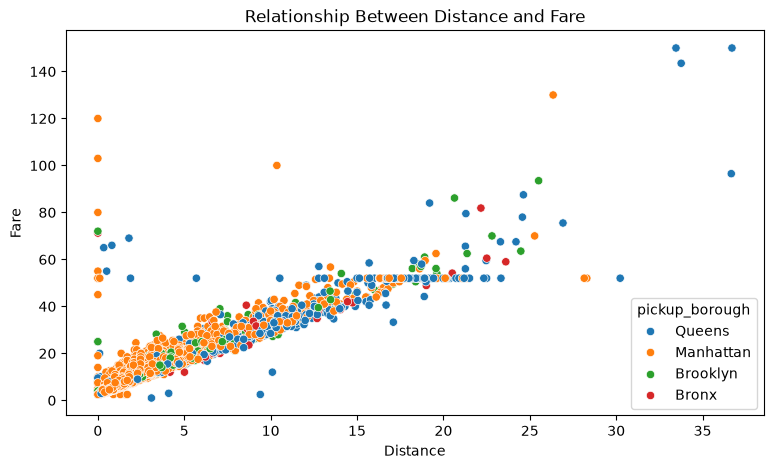

In [24]:
plt.figure(figsize=(9,5))

sns.scatterplot(data=df, x='distance', y='fare',
                hue='pickup_borough')

plt.title('Relationship Between Distance and Fare')
plt.xlabel('Distance')
plt.ylabel('Fare')
plt.show()

In [ ]:
#★ Heatmap
#Plot a heatmap to visualize the correlation between numerical variables such as
#distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the
#relationships.

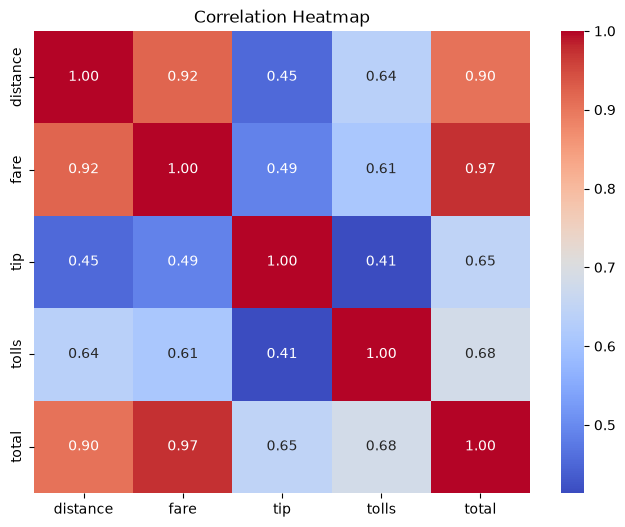

In [26]:
# Select numerical columns
corr = df[['distance', 'fare', 'tip', 'tolls', 'total']].corr()

# Plot heatmap
plt.figure(figsize=(8,6))

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

In [ ]:
#★ Pair Plot
#Create a pair plot to visualize the pairwise relationships between distance, fare, tip,
#and total. Color the data points according to the pickup_zone method to compare
#how different zones affect these variables.

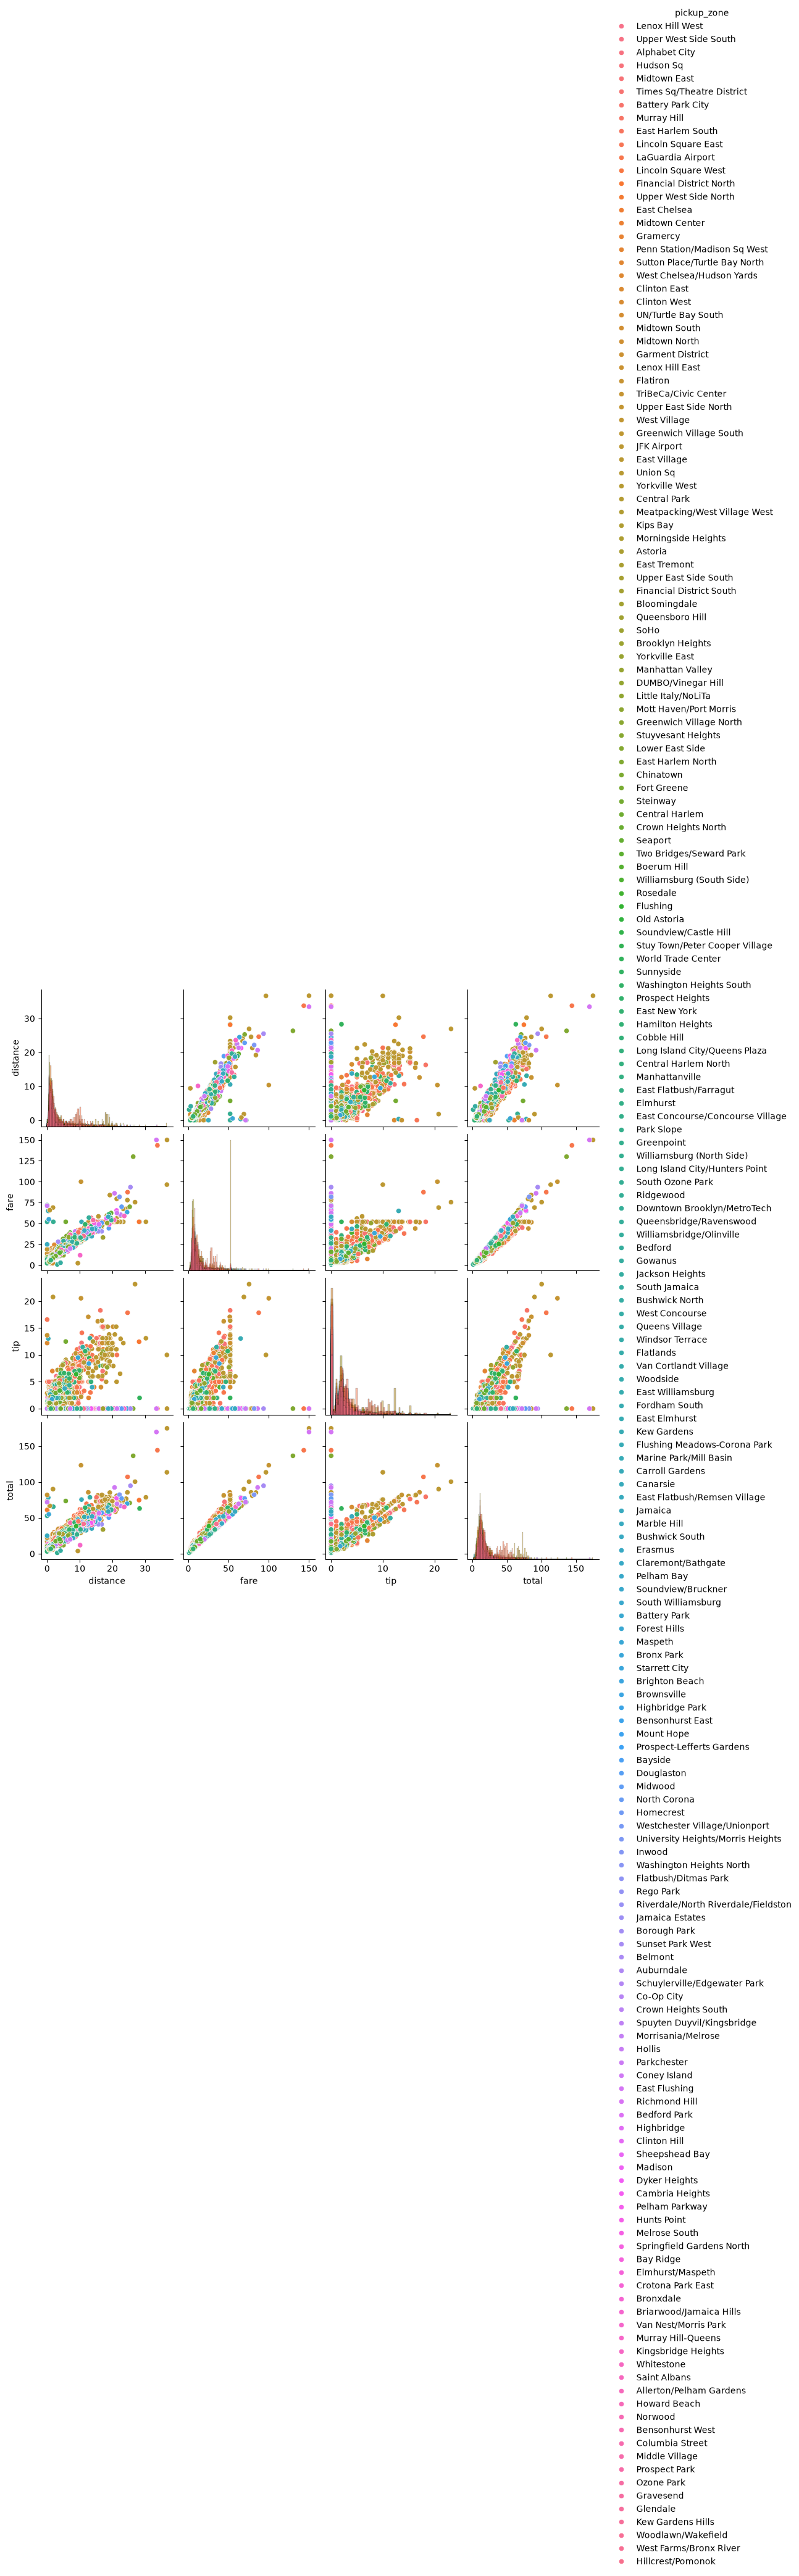

In [17]:
sns.pairplot(
    df[['distance', 'fare', 'tip', 'total', 'pickup_zone']].dropna(),
    hue='pickup_zone',
    diag_kind='hist'
)

plt.show()

In [ ]:
#★ Violin Plot
#Plot a violin plot to show the distribution of fare for each payment method. Use the
#payment method as the categorical axis and fare as the numeric axis to visualize its
#distribution.

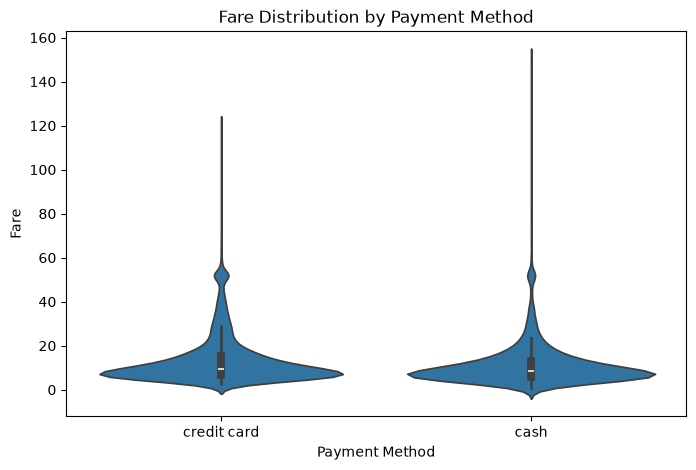

In [16]:
plt.figure(figsize=(8,5))

sns.violinplot(data=df, x='payment', y='fare')

plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare')
plt.show()  